# Deep models interpretability
This notebooks shows examples of approaches for interpretation of (pre-)trained model predictions.

In [1]:
%pip install scikit-image shap catboost

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 547.8/547.8 kB 1.2 MB/s eta 0:00:00-:--:--
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 28.8/28.8 MB 615.4 kB/s eta 0:00:0000:0100:02
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4/4 [catboost]3/4 [catboost]
Note: you may need to restart the kernel to use updated packages.


In [11]:
import urllib
!pip install torchvision
import skimage
import torch, torch.nn as nn
import torch.nn.functional as F
import torchvision.models

import numpy as np
from skimage.transform import resize
import matplotlib.pyplot as plt
%matplotlib inline

device = 'cuda' if torch.cuda.is_available() else 'cpu'
print('device:', device)

### please, don't remove the following line
x = torch.tensor([1], dtype=torch.float32).to(device)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.8/1.8 MB 115.2 kB/s eta 0:00:00a 0:00:03
device: cpu


In [12]:
import requests  # load imagenet class names
response = requests.get('https://s3.amazonaws.com/deep-learning-models/image-models/imagenet_class_index.json')
class_labels = {int(key): value for key, (code, value) in response.json().items()}
class_labels[897]

'washer'

### Task I: manual explanation with smoothgrad (2 points)

Let us begin by implementing our own little explainer for [DenseNet121](https://arxiv.org/abs/1608.06993) pretrained on ImageNet.

For the sake of simplicity, we're gonna rely on [SmoothGrad](https://arxiv.org/pdf/1706.03825.pdf) explainer - a simple average of gradients over noisy inputs.

In [13]:
model = torchvision.models.resnet50(pretrained=True).train(False).to(device)

/opt/anaconda3/lib/python3.13/site-packages/torchvision/models/_utils.py:207: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/opt/anaconda3/lib/python3.13/site-packages/torchvision/models/_utils.py:222: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=ResNet50_Weights.IMAGENET1K_V1`. You can also use `weights=ResNet50_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


Downloading: "https://download.pytorch.org/models/resnet50-0676ba61.pth" to /Users/swoodge/.cache/torch/hub/checkpoints/resnet50-0676ba61.pth


100%|██████████| 97.8M/97.8M [02:06<00:00, 811kB/s] 


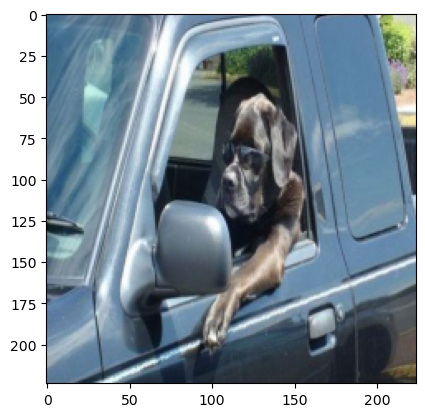

#1: p=0.853	bloodhound (163)
#2: p=0.039	washer (897)
#3: p=0.009	car_mirror (475)
#4: p=0.008	pickup (717)
#5: p=0.008	Weimaraner (178)
#6: p=0.007	Labrador_retriever (208)
#7: p=0.006	Chesapeake_Bay_retriever (209)
#8: p=0.005	limousine (627)
#9: p=0.004	pug (254)
#10: p=0.003	tub (876)


In [19]:
!curl -sL https://cdn2.adrianflux.co.uk/wp-fluxposure/uploads/2014/08/no-7.jpg -o img.jpg

image = resize(plt.imread('img.jpg')[..., :3] / 255.0, (224, 224))
plt.imshow(image)
plt.show()

with torch.no_grad():
    image_tensor = torch.as_tensor(image, device=device, dtype=torch.float32)
    image_tensor = image_tensor[None].permute(0, 3, 1, 2)
    probs = torch.softmax(model(image_tensor), dim=-1)[0]
    
for i, class_ix in enumerate(probs.argsort(descending=True)[:10]):
    print(f"#{i + 1}: p={probs[class_ix].item():.3f}\t{class_labels[class_ix.item()]} ({class_ix.item()})")

Now let's implement SmoothGrad itself.

In [20]:
def explain_smoothgrad(image: torch.Tensor, class_ix, num_runs=32, sigma=0.1):
    image_tensor = torch.as_tensor(image, device=device, dtype=torch.float32)
    image_tensor = image_tensor[None].permute(0, 3, 1, 2)  # shape: [1, 3, h, w]

    # 1. num_runs copies of the image
    images = image_tensor.repeat(num_runs, 1, 1, 1)                 # [num_runs, 3, h, w]
    # 2. independent N(0, sigma) noise for each copy
    noisy = (images + sigma * torch.randn_like(images)).requires_grad_(True)
    # 3. gradient of the class logit w.r.t. input pixels
    logits = model(noisy)                                           # [num_runs, num_classes]
    # summing over the batch is fine: each copy's logit depends only on its own input
    grads, = torch.autograd.grad(logits[:, class_ix].sum(), noisy)  # [num_runs, 3, h, w]
    # 4. average over the noisy copies
    # 5. reshape back to (h, w, 3)
    average_gradients = grads.mean(dim=0).permute(1, 2, 0).detach()

    assert tuple(average_gradients.shape) == image.shape
    return abs(average_gradients).cpu().numpy()

__Let's try it out!__ Peter Higgs nobel prize photo

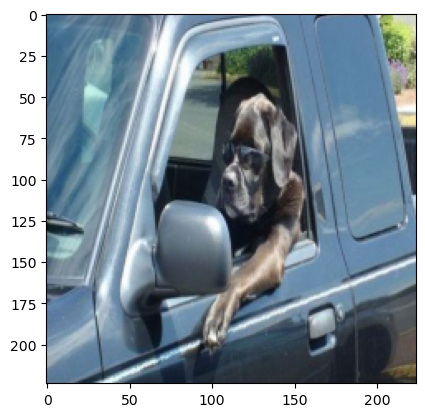

#1: p=0.853	bloodhound (163)
#2: p=0.039	washer (897)
#3: p=0.009	car_mirror (475)
#4: p=0.008	pickup (717)
#5: p=0.008	Weimaraner (178)
#6: p=0.007	Labrador_retriever (208)
#7: p=0.006	Chesapeake_Bay_retriever (209)
#8: p=0.005	limousine (627)
#9: p=0.004	pug (254)
#10: p=0.003	tub (876)


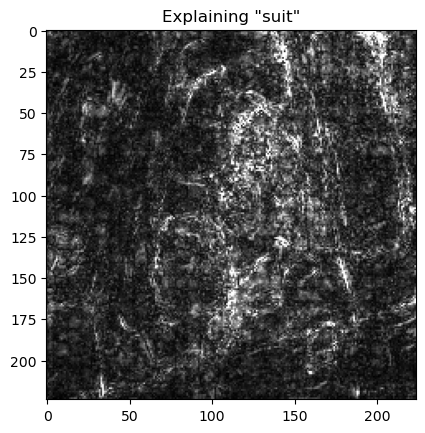

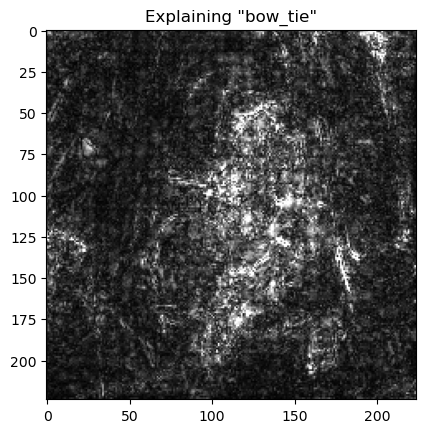

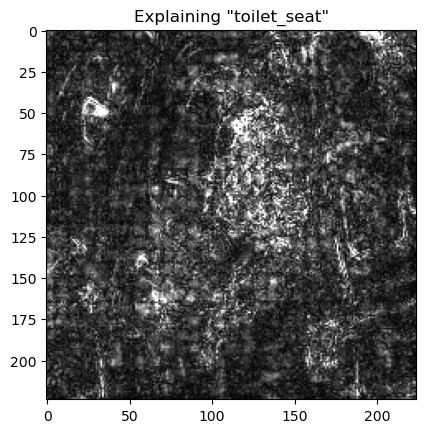

In [27]:
!curl -sL https://i.pinimg.com/originals/3a/e1/83/3ae18369ab2e86be83e637ad702ec832.jpg -O img.jpg

image = resize(plt.imread('img.jpg')[..., :3] / 255.0, (224, 224))
plt.imshow(image)
plt.show()

with torch.no_grad():
    image_tensor = torch.as_tensor(image, device=device, dtype=torch.float32)
    image_tensor = image_tensor[None].permute(0, 3, 1, 2)
    probs = torch.softmax(model(image_tensor), dim=-1)[0]
    
for i, class_ix in enumerate(probs.argsort(descending=True)[:10]):
    print(f"#{i + 1}: p={probs[class_ix].item():.3f}\t{class_labels[class_ix.item()]} ({class_ix.item()})")
    
for class_ix in 834, 457, 861:
    sal = explain_smoothgrad(image, class_ix).max(axis=-1)    # (224, 224)
    sal = np.clip(sal / np.percentile(sal, 99), 0, 1)         # normalize, clip outliers
    plt.title(f'Explaining "{class_labels[class_ix]}"')
    plt.imshow(sal, cmap='gray')
    plt.show()

### SHapley Additive exPlanations
Now, let's try something heavier. The current state of the art in explaining model predictions is [SHAP](https://arxiv.org/abs/1705.07874): Shapley Additive Explanations.

This method is based on [Shapley values](https://en.wikipedia.org/wiki/Shapley_value) - a game-theoretic concept that evaluates the contribution of individual players in a cooperative game. Except this time our "players" are input features and the "game" is predicting whichever output the model gave.

Computing Shapley values naively requires $O(F!)$ time where F is the number of features. To make this computation more feasible, authors [proposed](https://arxiv.org/abs/1705.07874) several approximations, one of which relies on averaged gradients. This approximation also requires "background" data - other images similar to the ones in question that can be used as reference points.

In [25]:
import shap
# load "background" images - some 50 random images from ImageNet used as "other data points" for SHAP
background, _ = shap.datasets.imagenet50()
background = torch.as_tensor(background / 255.0, device=device, dtype=torch.float32)
background = background.permute(0, 3, 1, 2)
background.size()

torch.Size([50, 3, 224, 224])

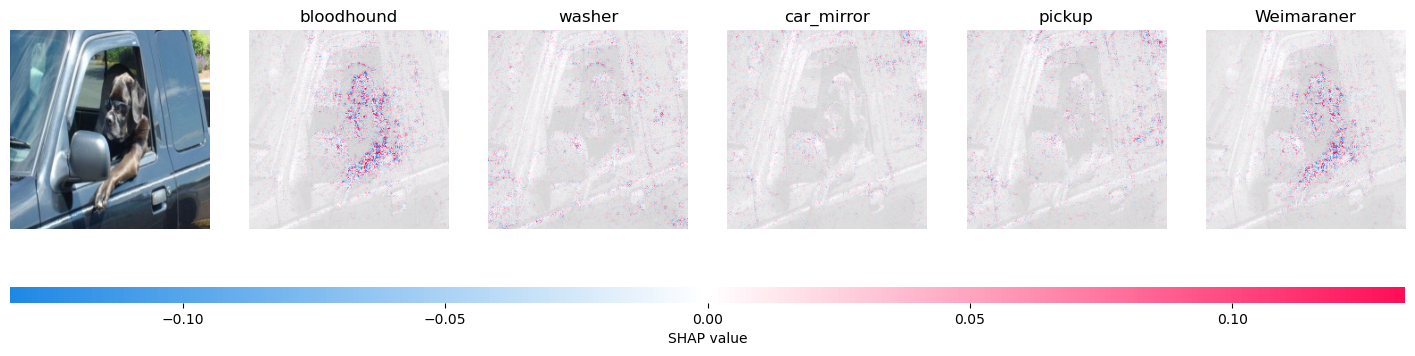

In [26]:
shap.initjs()  # run it before every (interactive) shap visualizer in colab
# v-- image to explain. If you're not using a GPU, this may take up to 20 minutes.
!curl -sL https://i.pinimg.com/originals/32/da/5c/32da5c3314fcc5ebf1a7b7d1548fcb03.jpg -O img.jpg
image = resize(plt.imread('img.jpg')[..., :3] / 255.0, (224, 224))
image_tensor = torch.as_tensor(image[None], device=device, dtype=torch.float32).permute(0, 3, 1, 2)
explainer = shap.GradientExplainer((model, model.conv1), background)
shap_values, indices = explainer.shap_values(image_tensor, ranked_outputs=5, nsamples=200)
shap.image_plot(shap_values=list(np.transpose(shap_values, (4, 0, 2, 3, 1))),
                pixel_values=image_tensor.permute(0, 2, 3, 1).cpu().numpy(),
                labels=np.vectorize(lambda i: class_labels[i])(indices.cpu().numpy()))

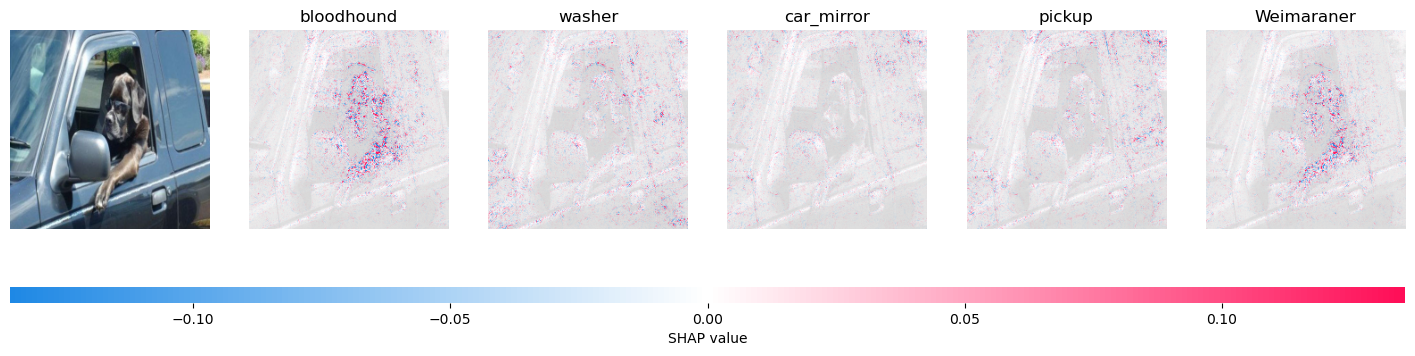

In [28]:
shap.initjs() # obligatory physicist reference
!curl -sL https://images-na.ssl-images-amazon.com/images/I/51ArQaCkkZL._AC_.jpg -O img.jpg
image = resize(plt.imread('img.jpg')[..., :3] / 255.0, (224, 224))
image_tensor = torch.as_tensor(image[None], device=device, dtype=torch.float32).permute(0, 3, 1, 2)
explainer = shap.GradientExplainer((model, model.conv1), background)
shap_values, indices = explainer.shap_values(image_tensor, ranked_outputs=5, nsamples=200)
shap.image_plot(shap_values=list(np.transpose(shap_values, (4, 0, 2, 3, 1))),
                pixel_values=image_tensor.permute(0, 2, 3, 1).cpu().numpy(),
                labels=np.vectorize(lambda i: class_labels[i])(indices.cpu().numpy()))

###### Explaining classical machine learning models

Finally, let's see how SHAP explainers can be applied to more conventional machine learning models like gradient boosting. 

Spoiler: exactly the same from a user's perspective. However, this time we're gonna use a different Shapley approximation implemented in TreeExplainer. For a full set of available explainers, take a look at their official [examples page](https://github.com/slundberg/shap/tree/master/notebooks).

**NB: the following cells requires JavaScript support and should work in Jupyter (not JupyterLab or cocalc)**. 
In that case try running it on Google colab: https://colab.research.google.com/github/yandexdataschool/mlhep2020-assignments/blob/master/notebooks/interpretability/interpretability_demo.ipynb

In [29]:
import catboost # pip install catboost
from sklearn.datasets import fetch_california_housing
california = fetch_california_housing(as_frame=True)
X, y = california.data, california.target.values
ensemble = catboost.CatBoostRegressor(iterations=100, learning_rate=0.1)
ensemble.fit(X, y, verbose=False, plot=False)
explainer = shap.TreeExplainer(ensemble)
shap_values = explainer.shap_values(X)

shap.initjs() # visualize explanation of the first example
shap.force_plot(explainer.expected_value, shap_values[0, :], X.iloc[0, :])

In [30]:
# Explain training data: each *column* is a rotated plot from above, stacked for all training samples
shap.initjs() # (this plot is interactive, hover mouse to see feature names)
shap.force_plot(explainer.expected_value, shap_values[::100], X[::100])

### Task II: Explain Intermediate Layers of Resnet50 on ImageNet (3 points)

Sometimes, computing explanations w.r.t. pixels is more difficult (and less interpretable) than using intermediate layers that are closer to the "output" layer. The trick is to compute low-resolution explanations of output w.r.t. intermediate layer and then resizing them to fit the original image.

Each layer in deep CNN learns filters of increasing complexity. The first layers learn basic feature detection filters such as edges and corners. The middle layers learn filters that detect parts of objects — for faces, they might learn to respond to features like eyes and brows, and deeper layers capture entire objects.

**Your task** is to explain ResNet50 model outputs with respect to the convolution module from 1st, 2nd, 3rd and 4th layer of the pretrained Resnet50 network using the same GradientExplainer. *The task may require some googling or browsing the [docs](https://shap.readthedocs.io/en/latest) :)* A good starting point is from [this example](https://shap.readthedocs.io/en/latest/example_notebooks/image_examples/image_classification/Explain%20an%20Intermediate%20Layer%20of%20VGG16%20on%20ImageNet%20%28PyTorch%29.html), but for ResNet50 and on different images.

**Please use at least 10 images from across the internet (or from ImageNet) and compare the 2nd and 4th layer explanations on these images.**


In [31]:
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
import matplotlib.pyplot as plt
import shap
import requests
from io import BytesIO
from PIL import Image, ImageOps
 
 
class Normalize(nn.Module):
    def __init__(self, mean, std):
        super().__init__()
        self.register_buffer("mean", torch.tensor(mean).view(1, 3, 1, 1))
        self.register_buffer("std", torch.tensor(std).view(1, 3, 1, 1))
 
    def forward(self, x):
        return (x - self.mean) / self.std
 
 
resnet = torchvision.models.resnet50(weights=torchvision.models.ResNet50_Weights.IMAGENET1K_V1)
resnet50 = nn.Sequential(
    Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]), resnet
).to(device).eval()

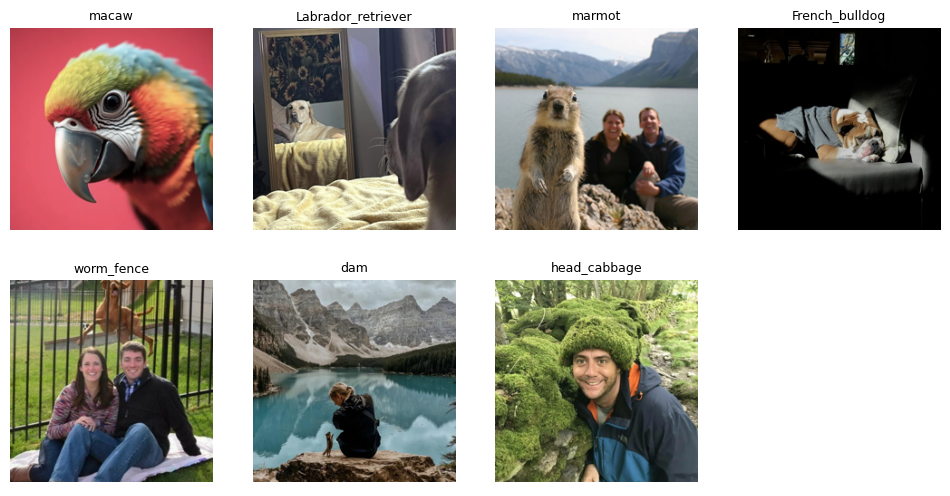

In [33]:
def load_image(url):
    r = requests.get(url, headers={"User-Agent": "Mozilla/5.0"}, timeout=30)
    r.raise_for_status()
    img = Image.open(BytesIO(r.content)).convert("RGB")
    img = ImageOps.fit(img, (224, 224))  # center-crop to a square, then resize
    return np.asarray(img, dtype=np.float32) / 255.0
 
 
urls = [
    "https://cdn.venngage.com/features/img/AI_Image_Generator_Sample_3.webp", 
    "https://wl-brightside.cf.tsp.li/resize/728x/jpg/2f5/018/6e09f15130bba3498cc7f62a35.jpg",
    "https://i2-prod.mirror.co.uk/incoming/article1348008.ece/ALTERNATES/s1227b/Best-photobombing-pictures.jpg",
    "https://wl-brightside.cf.tsp.li/resize/728x/jpg/2b9/39e/6b154151258e3a16d816999f8b.jpg",
    "https://travelask.ru/system/images/files/001/494/468/wysiwyg_jpg/14.jpg?1633538891",
    "https://avatars.mds.yandex.net/i?id=e69324cf93481f89cadbeed730976b00_l-9227708-images-thumbs&n=13",
    "https://avatars.mds.yandex.net/i?id=b397d75a59cddb61270822fb47e5fd13_l-12371956-images-thumbs&n=13"
]
images = np.stack([load_image(u) for u in urls])                     # (N, 224, 224, 3) in [0, 1]
to_explain = torch.tensor(images).permute(0, 3, 1, 2).to(device)     # (N, 3, 224, 224)
 
X_bg, _ = shap.datasets.imagenet50()                                 # 50 ImageNet images, 0..255
background = torch.tensor(X_bg / 255.0, dtype=torch.float32).permute(0, 3, 1, 2).to(device)
 
# sanity check: what does the model predict?
with torch.no_grad():
    top1 = resnet50(to_explain).argmax(-1).cpu().numpy()
ncols = (len(images) + 1) // 2
fig, axes = plt.subplots(2, ncols, figsize=(3 * ncols, 6))
for ax, img, c in zip(axes.flat, images, top1):
    ax.imshow(img)
    ax.set_title(str(class_labels[int(c)])[:25], fontsize=9)
for ax in axes.flat:
    ax.axis("off")
plt.show()

In [34]:
layers = {
    "layer1": resnet.layer2,   # output of layer1: 256  x 56 x 56
    "layer2": resnet.layer3,   # output of layer2: 512  x 28 x 28
    "layer3": resnet.layer4,   # output of layer3: 1024 x 14 x 14
    "layer4": resnet.avgpool,  # output of layer4: 2048 x 7  x 7
}
 
 
def to_image_plot_format(sv):
    """shap >= 0.45 returns one array (N, C, h, w, K); older versions return a list of K arrays
    (N, C, h, w). shap.image_plot wants a list of K arrays (N, h, w, C)."""
    if isinstance(sv, list):
        sv = np.stack(sv, axis=-1)
    if sv.ndim == 4:
        sv = sv[..., None]
    return [np.moveaxis(sv[..., k], 1, -1) for k in range(sv.shape[-1])]
 
 
results = {}
for name, layer in layers.items():
    explainer = shap.GradientExplainer((resnet50, layer), background)
    sv, idx = explainer.shap_values(to_explain, ranked_outputs=2, nsamples=200)
    results[name] = (to_image_plot_format(sv), np.asarray(idx.cpu()))
    print(name, results[name][0][0].shape)  # (N, h, w, C)
 

layer1 (7, 56, 56, 256)
layer2 (7, 28, 28, 512)
layer3 (7, 14, 14, 1024)
layer4 (7, 7, 7, 2048)


===== explanations w.r.t. layer2 =====


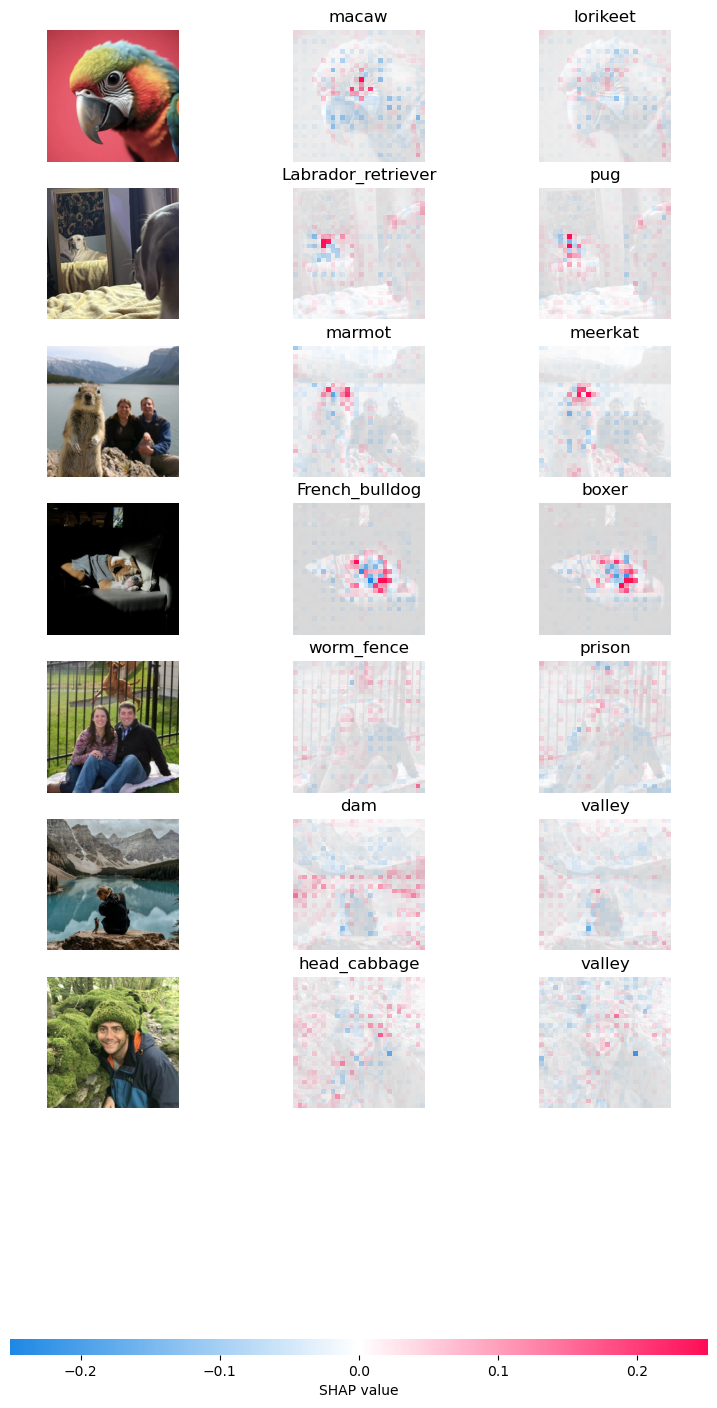

===== explanations w.r.t. layer4 =====


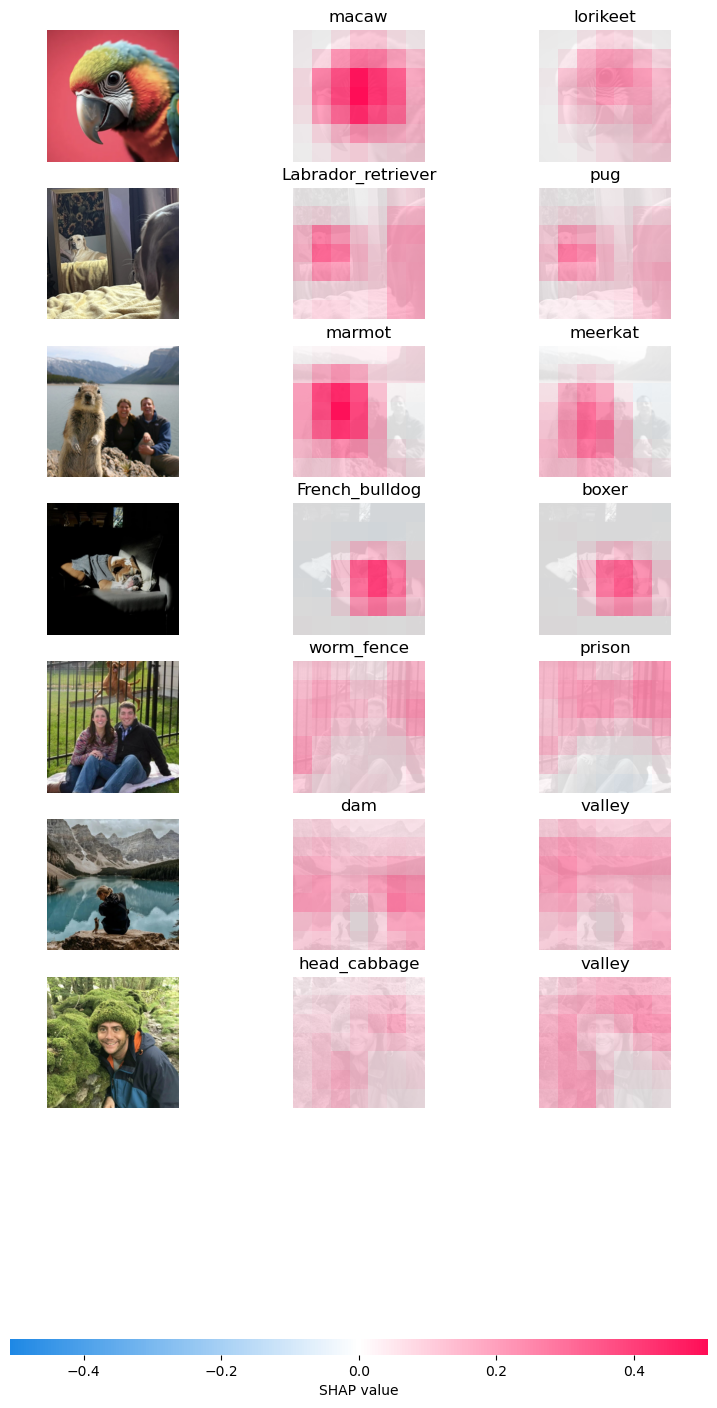

In [36]:
for name in ["layer2", "layer4"]:
    sv, idx = results[name]
    labels = np.vectorize(lambda i: str(class_labels[int(i)]))(idx)
    print(f"===== explanations w.r.t. {name} =====")
    shap.image_plot(sv, images, labels)
 


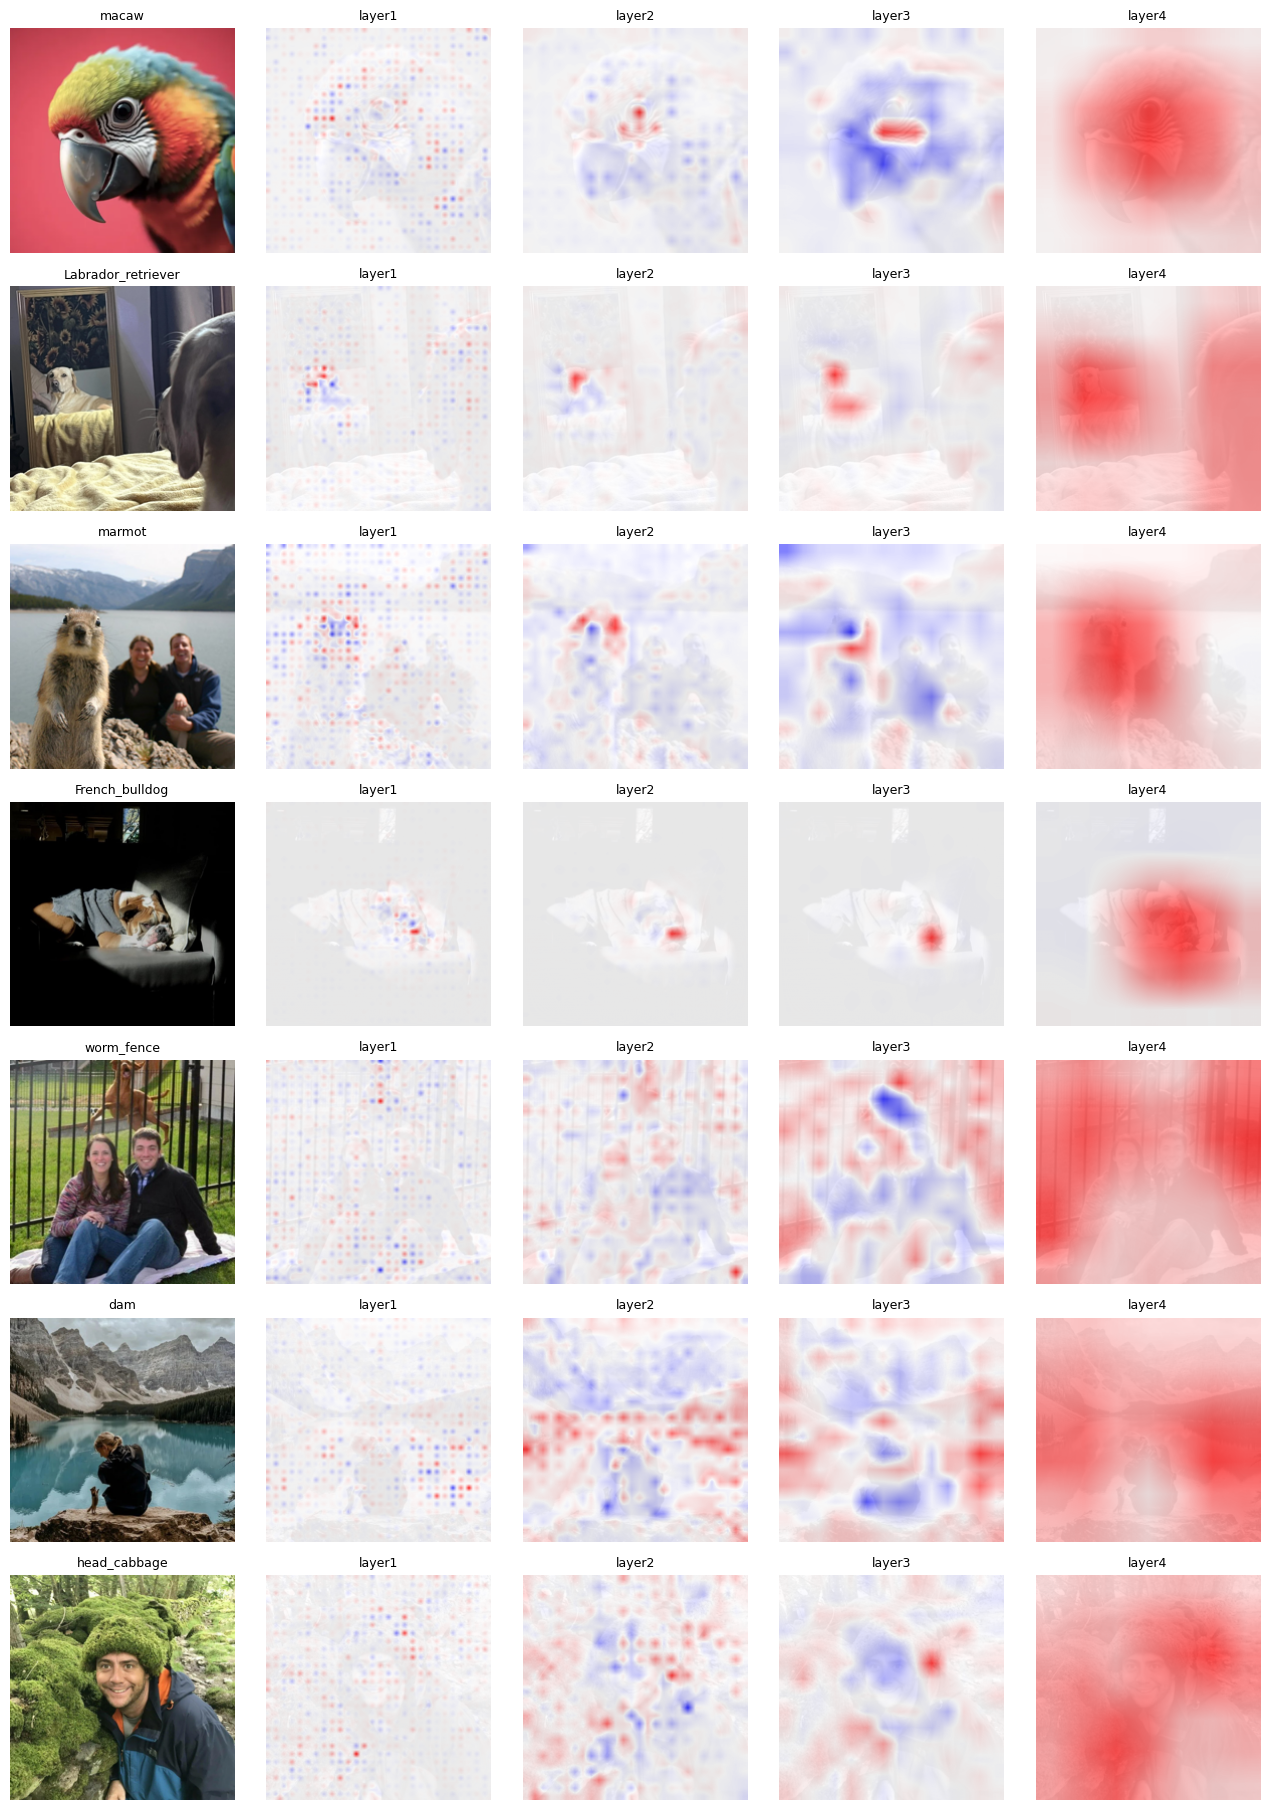

In [35]:
def upsampled_map(sv_top1, n):
    m = torch.tensor(sv_top1[n].sum(-1))[None, None]  # (1, 1, h, w)
    return F.interpolate(m, size=images.shape[1:3], mode="bilinear", align_corners=False)[0, 0].numpy()
 
 
names = list(layers)
fig, axes = plt.subplots(len(images), len(names) + 1,
                         figsize=(2.6 * (len(names) + 1), 2.6 * len(images)))
for n in range(len(images)):
    c = results[names[0]][1][n, 0]
    axes[n, 0].imshow(images[n])
    axes[n, 0].set_title(str(class_labels[int(c)])[:25], fontsize=9)
    for j, name in enumerate(names, start=1):
        m = upsampled_map(results[name][0][0], n)
        lim = np.abs(m).max()
        axes[n, j].imshow(images[n].mean(-1), cmap="gray", alpha=0.3)
        axes[n, j].imshow(m, cmap="bwr", vmin=-lim, vmax=lim, alpha=0.7)
        axes[n, j].set_title(name, fontsize=9)
for ax in axes.flat:
    ax.axis("off")
plt.tight_layout()
plt.show()

## References

* SHAP explainer based on superpixels - [notebook](https://slundberg.github.io/shap/notebooks/ImageNet%20VGG16%20Model%20with%20Keras.html)
* SHAP reference notebook - [view on github](https://github.com/slundberg/shap/tree/master/notebooks)
* More various explainers in [ELI5](https://github.com/TeamHG-Memex/eli5)
* Same notebook on Google [Colab](https://colab.research.google.com/github/yandexdataschool/mlhep2020-assignments/blob/master/notebooks/interpretability/interpretability_demo.ipynb)